# Statistical Arbitrage in Cryptocurrencies - Version 2

**Wall Street Quants - Bootcamp Project.** Momentum and reversal research on a survivorship-free universe of
39 coins, revised after trainer feedback. Data 2021-01-01 to 2026-10-08.

**Hold-out result first (2024-01-01 to 2026-10-08, never used for any decision):** combined portfolio
Sharpe **0.20** (mean / std x sqrt(252)), alpha 2.8% a year with t = **0.52**,
beta -0.03, correlation to BTC **-0.12**. Research period (2021-2023): Sharpe 0.93,
alpha t 1.64.

| Trainer comment | Version 2 change |
|---|---|
| Sharpe used sqrt(365) | `sa_core.ANN = 252`: Sharpe = mean / std x sqrt(252) |
| Hold-out contaminated by full-sample exploration | Mechanical protocol: directions, candidates, books, execution and weighting all chosen on 2021-2023 only |
| Lead with hold-out, add correlation to BTC | Hold-out first in every table; `Corr BTC` column added |
| 16 survivors | Top 40 coins by market cap on 2021-01-03 (ex stablecoins / wrapped), delisted coins kept |
| Explain and rebuild | `src/minimal_backtest.py` (60 lines, checked against the engine) and `V2_methodology_explainer.docx` |


## 0. Setup

In [1]:
import os, sys, json, inspect, subprocess, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sys.path.insert(0, "src")

REFRESH_DATA = False   # True: rebuild the universe and download prices (hourly takes ~1 hour)
RUN_PAIRS = False      # True: re-run the cointegration engine (~6 minutes)

## 1. Universe and data
The universe is fixed by market cap on 2021-01-03, so it includes coins that later failed. Each coin's prices come from the venue with the most complete history.

In [2]:
if REFRESH_DATA:
    subprocess.run([sys.executable, "src/fetch_data.py"], check=True)
uni = pd.read_csv("data/universe.csv")
print(uni.status.value_counts().to_string())
uni[["cmc_rank", "asset", "name", "status", "reason", "source", "first", "last"]]

status
in universe    39
excluded        5
dropped         1


,cmc_rank,asset,name,status,reason,source,first,last
0,1,BTC,Bitcoin,in universe,NaN,coinbase,2021-01-01,2026-10-08
1,2,ETH,Ethereum,in universe,NaN,coinbase,2021-01-01,2026-10-08
2,3,USDT,Tether,excluded,stablecoin,NaN,NaN,NaN
3,4,LTC,Litecoin,in universe,NaN,coinbase,2021-01-01,2026-10-08
4,5,XRP,XRP,in universe,NaN,kucoin,2021-01-01,2026-10-08
5,6,DOT,Polkadot,in universe,NaN,kucoin,2021-01-01,2026-10-08
6,7,BCH,Bitcoin Cash,in universe,NaN,coinbase,2021-01-01,2026-10-08
7,8,ADA,Cardano,in universe,NaN,kucoin,2021-01-01,2026-10-08
8,9,BNB,Binance Coin,in universe,NaN,gate,2021-01-01,2026-10-08
9,10,LINK,Chainlink,in universe,NaN,coinbase,2021-01-01,2026-10-08


39 coins, 2021-01-01 to 2026-10-08
Annualisation: 252 | research ends 2023-12-31 | hold-out starts 2024-01-01


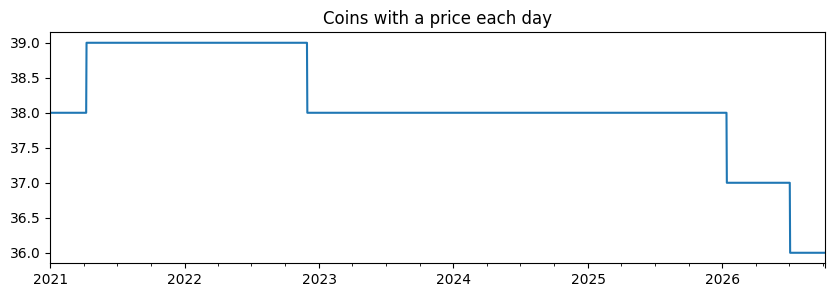

In [3]:
import sa_core as C
close, rets, dollar_vol = C.load_panel()
print(f"{close.shape[1]} coins, {close.index.min().date()} to {close.index.max().date()}")
print("Annualisation:", C.ANN, "| research ends", C.IS_END, "| hold-out starts", C.OOS_START)
ax = close.notna().sum(axis=1).loc["2021-01-01":].plot(figsize=(10, 3), title="Coins with a price each day")
plt.show()

## 2. The backtest engine, and a 60-line rebuild
Weights use data up to day t's close and earn day t+1's return; gross exposure is 1; cost = turnover x bps. `minimal_backtest.py` rebuilds one strategy from scratch and asserts it matches the engine.

In [4]:
for f in [C.cs_weights, C.ts_weights, C.hold, C.backtest, C.sharpe, C.alpha_beta]:
    print(inspect.getsource(f))

def cs_weights(signal, direction=1):
    """Cross-sectional dollar-neutral weights proportional to the demeaned
    cross-sectional rank of `signal`.  direction=+1 momentum, -1 reversal."""
    r = signal.rank(axis=1, pct=True)
    r = r.sub(r.mean(axis=1), axis=0)
    return normalise(direction * r)

def ts_weights(signal, vol=None, direction=1):
    """Time-series weights: sign of each asset's own signal, optionally
    inverse-volatility scaled, then gross-normalised."""
    w = direction * np.sign(signal)
    if vol is not None:
        w = w / vol
    return normalise(w.replace([np.inf, -np.inf], np.nan).fillna(0))

def hold(w, h):
    """Overlapping-portfolio holding period (Jegadeesh-Titman): average of the
    last h daily target portfolios.  Cuts turnover roughly by a factor h."""
    if h <= 1:
        return w
    return normalise(w.rolling(h, min_periods=1).mean())

def backtest(w, rets, cost_bps=MARKET_BPS, start=BT_START, end=None):
    """Unconstrained daily backtest.  R

In [5]:
print(subprocess.run([sys.executable, "src/minimal_backtest.py"], capture_output=True, text=True).stdout)

Reversal L=60 skip=14 hold=14 at 7 bps
  Sharpe full 0.132 | research 0.480 | hold-out -0.164
  ann. return 2.0% | ann. vol 15.5% | max DD -44.8%
  alpha 1.7%/yr | beta 0.015 | corr BTC 0.042
  avg daily turnover 0.059
  matches sa_core engine (max daily difference 0.0e+00)



## 3. Run the pipeline

In [6]:
if RUN_PAIRS:
    print(subprocess.run([sys.executable, "src/statarb.py"], capture_output=True, text=True).stdout[-1200:])
import research as RS
RS.main()
S = json.load(open("data/research/summary.json"))
rd = lambda n: pd.read_csv(f"data/research/{n}.csv")

Panel 2021-01-01 -> 2026-10-08, 39 assets
A. horizon


A2/C/E. intraday


B. activity


D. themes


F. correlation


...

H. candidates


   momentum book: ['Theme L=14 MOM H=7', 'TS L=blend + DVOL filter MOM H=1']
   reversal book: ['Residual vs theme L=60 REV H=7', 'CS L=120 REV H=7', 'Residual vs market L=60 REV H=7']


   execution chosen on IS: {'Momentum': 'No-trade band 2%', 'Reversal': 'Hold 3d (overlapping)'}


   weighting chosen on IS: Inverse volatility



=== HOLD-OUT ===
                                 Ann.Return  Ann.Vol  Sharpe  MaxDD  Alpha   Beta  Alpha t  Corr BTC
Strategy                                                                                           
Combined portfolio                   0.021    0.103   0.201 -0.267  0.028 -0.031    0.518    -0.117
Combined (all trades at 20bps)       0.011    0.103   0.110 -0.277  0.019 -0.031    0.345    -0.117
Momentum book (20bps market)         0.052    0.173   0.301 -0.248  0.072 -0.081    0.796    -0.183
Momentum book (7bps limit)           0.106    0.173   0.611 -0.186  0.125 -0.081    1.396    -0.184
Reversal book (7bps limit)          -0.010    0.144  -0.068 -0.354 -0.012  0.010   -0.163     0.027
Reversal book (20bps market)        -0.028    0.144  -0.193 -0.382 -0.030  0.010   -0.402     0.027
Cointegrated pairs (20bps)           0.027    0.043   0.642 -0.056  0.026  0.007    1.197     0.063
Equal-weight crypto (B&H)            0.101    0.525   0.193 -0.744 -0.152  1.050 

## 4. Performance - hold-out first

In [7]:
cols = ["Ann.Return", "Ann.Vol", "Sharpe", "MaxDD", "Alpha", "Beta", "Alpha t", "Corr BTC"]
for name, f in [("HOLD-OUT (never used for decisions)", "J_performance_oos"),
                ("Research period (all decisions)", "J_performance_is"), ("Full backtest", "J_performance_full")]:
    print(name); display(rd(f).set_index("Strategy")[cols])

HOLD-OUT (never used for decisions)


,Ann.Return,Ann.Vol,Sharpe,MaxDD,Alpha,Beta,Alpha t,Corr BTC
Strategy,,,,,,,,
Combined portfolio,0.021,0.103,0.201,-0.267,0.028,-0.031,0.518,-0.117
Combined (all trades at 20bps),0.011,0.103,0.110,-0.277,0.019,-0.031,0.345,-0.117
Momentum book (20bps market),0.052,0.173,0.301,-0.248,0.072,-0.081,0.796,-0.183
Momentum book (7bps limit),0.106,0.173,0.611,-0.186,0.125,-0.081,1.396,-0.184
Reversal book (7bps limit),-0.010,0.144,-0.068,-0.354,-0.012,0.010,-0.163,0.027
Reversal book (20bps market),-0.028,0.144,-0.193,-0.382,-0.030,0.010,-0.402,0.027
Cointegrated pairs (20bps),0.027,0.043,0.642,-0.056,0.026,0.007,1.197,0.063
Equal-weight crypto (B&H),0.101,0.525,0.193,-0.744,-0.152,1.050,-0.921,0.789
Buy & Hold BTC,0.241,0.394,0.612,-0.531,0.000,1.000,0.329,1.000


Research period (all decisions)


,Ann.Return,Ann.Vol,Sharpe,MaxDD,Alpha,Beta,Alpha t,Corr BTC
Strategy,,,,,,,,
Combined portfolio,0.094,0.101,0.933,-0.133,0.096,-0.032,1.645,-0.146
Combined (all trades at 20bps),0.082,0.101,0.811,-0.141,0.083,-0.032,1.434,-0.146
Momentum book (20bps market),0.112,0.206,0.543,-0.171,0.117,-0.125,1.078,-0.277
Momentum book (7bps limit),0.166,0.206,0.807,-0.149,0.171,-0.125,1.588,-0.279
Reversal book (7bps limit),0.082,0.125,0.658,-0.165,0.082,0.011,1.183,0.042
Reversal book (20bps market),0.063,0.125,0.502,-0.178,0.062,0.011,0.902,0.042
Cointegrated pairs (20bps),-0.053,0.059,-0.905,-0.149,-0.054,0.012,-1.680,0.091
Equal-weight crypto (B&H),-0.072,0.558,-0.128,-0.712,-0.117,1.053,-0.679,0.864
Buy & Hold BTC,0.043,0.458,0.094,-0.670,0.000,1.000,3.652,1.000


Full backtest


,Ann.Return,Ann.Vol,Sharpe,MaxDD,Alpha,Beta,Alpha t,Corr BTC
Strategy,,,,,,,,
Combined portfolio,0.052,0.102,0.505,-0.267,0.057,-0.031,1.421,-0.130
Combined (all trades at 20bps),0.041,0.102,0.401,-0.277,0.046,-0.031,1.154,-0.130
Momentum book (20bps market),0.077,0.188,0.411,-0.248,0.093,-0.102,1.340,-0.230
Momentum book (7bps limit),0.131,0.187,0.699,-0.186,0.147,-0.103,2.122,-0.231
Reversal book (7bps limit),0.029,0.136,0.212,-0.361,0.027,0.011,0.520,0.033
Reversal book (20bps market),0.010,0.136,0.075,-0.402,0.009,0.011,0.165,0.033
Cointegrated pairs (20bps),-0.007,0.050,-0.131,-0.198,-0.008,0.009,-0.430,0.078
Equal-weight crypto (B&H),0.028,0.539,0.053,-0.744,-0.138,1.052,-1.149,0.824
Buy & Hold BTC,0.158,0.422,0.374,-0.670,-0.000,1.000,-1.356,1.000


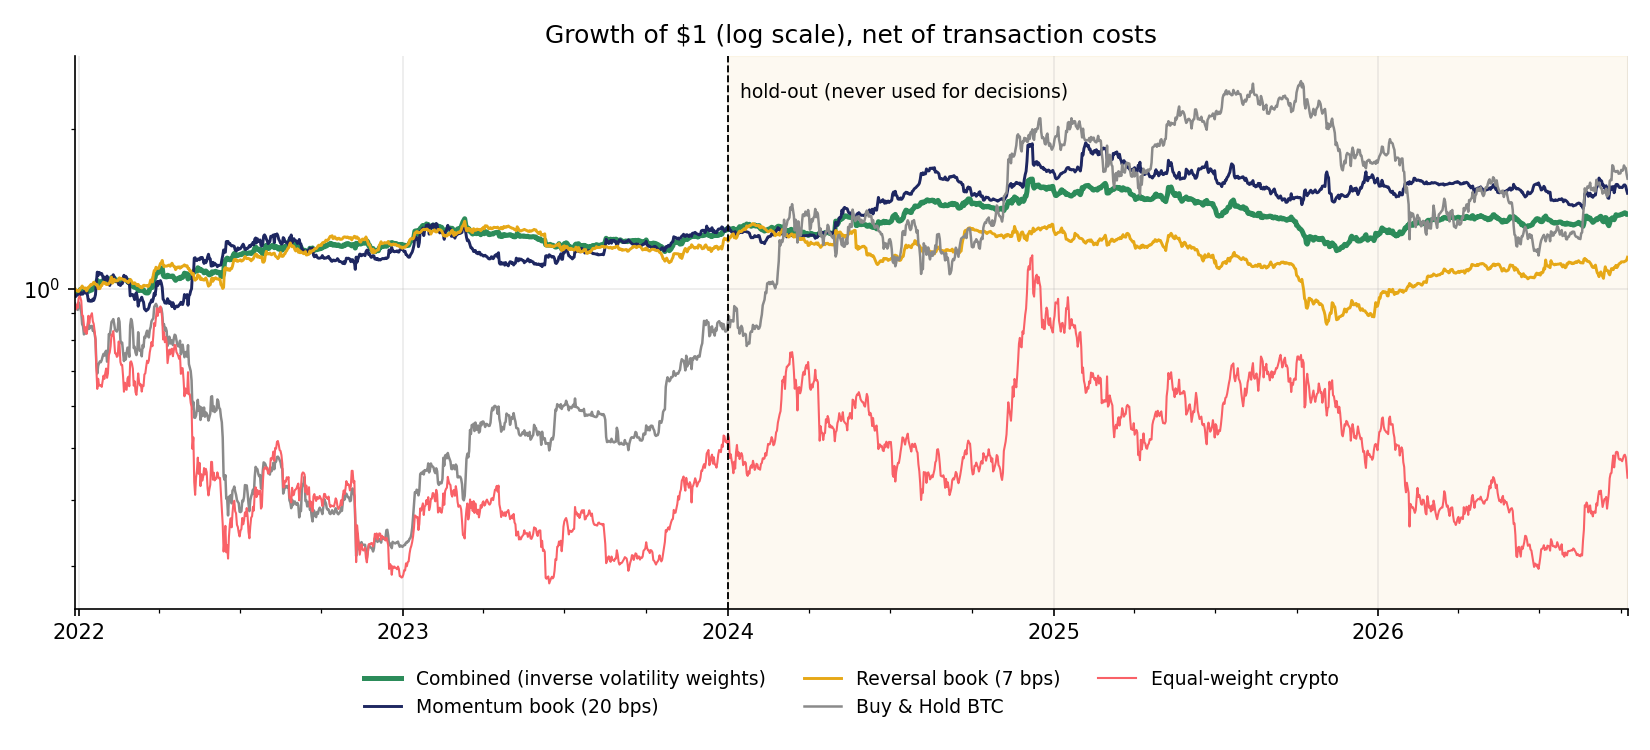

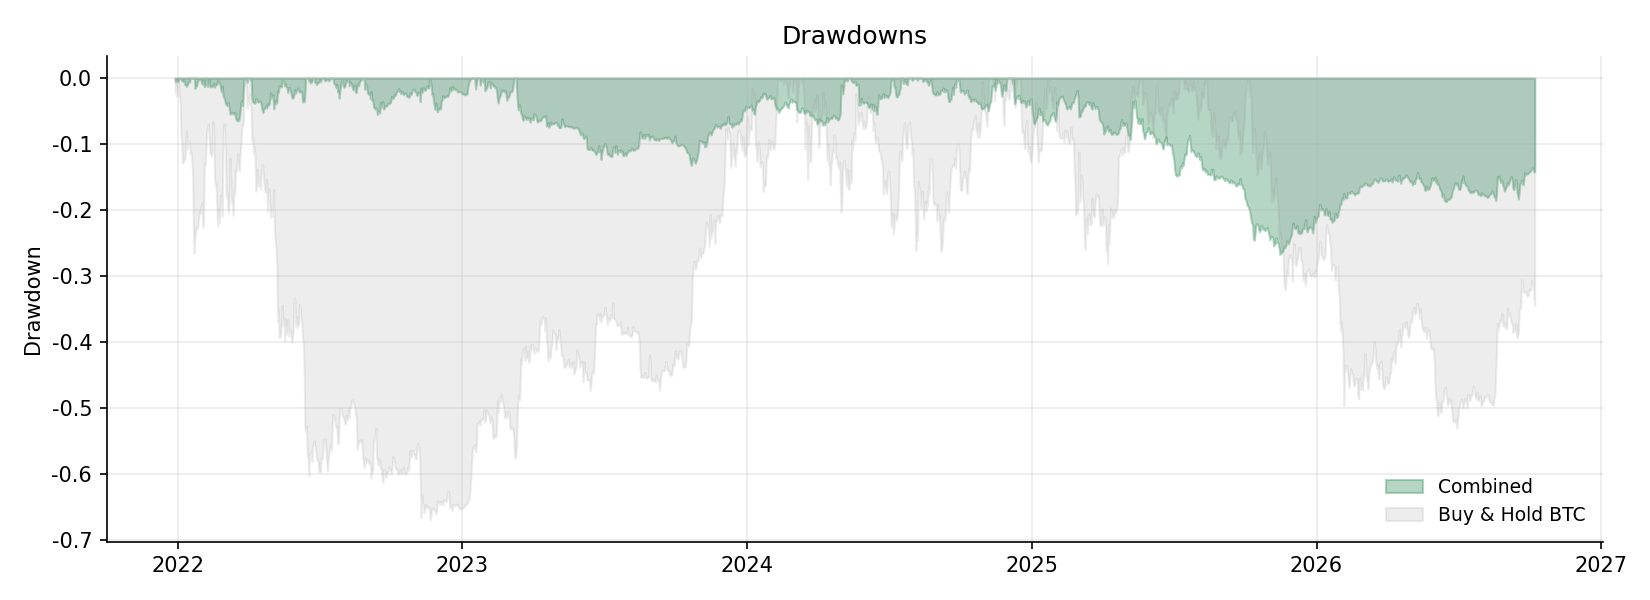

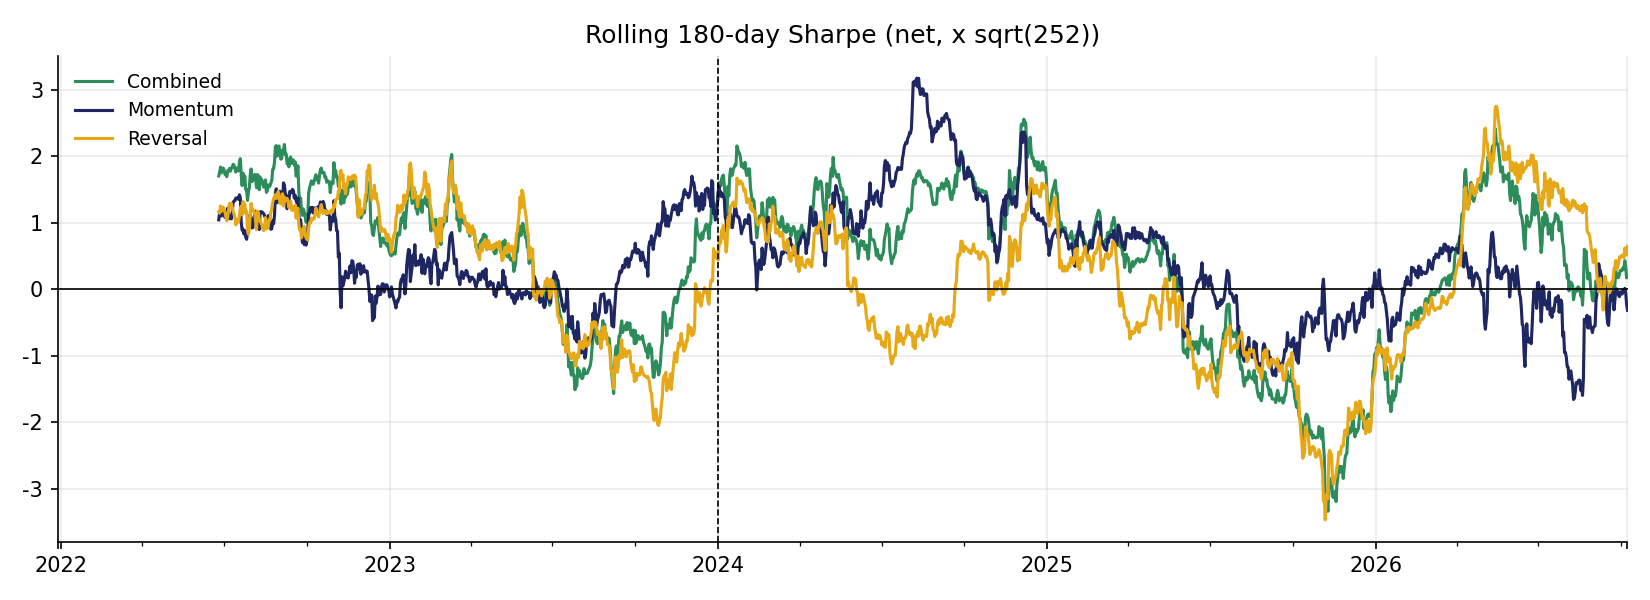

In [8]:
display(Image("figures/J_equity_curves.png")); display(Image("figures/J_drawdowns.png"))
display(Image("figures/J_rolling_sharpe.png"))

## 5. Exploration (research period drives decisions)
### 5.1 Time horizon

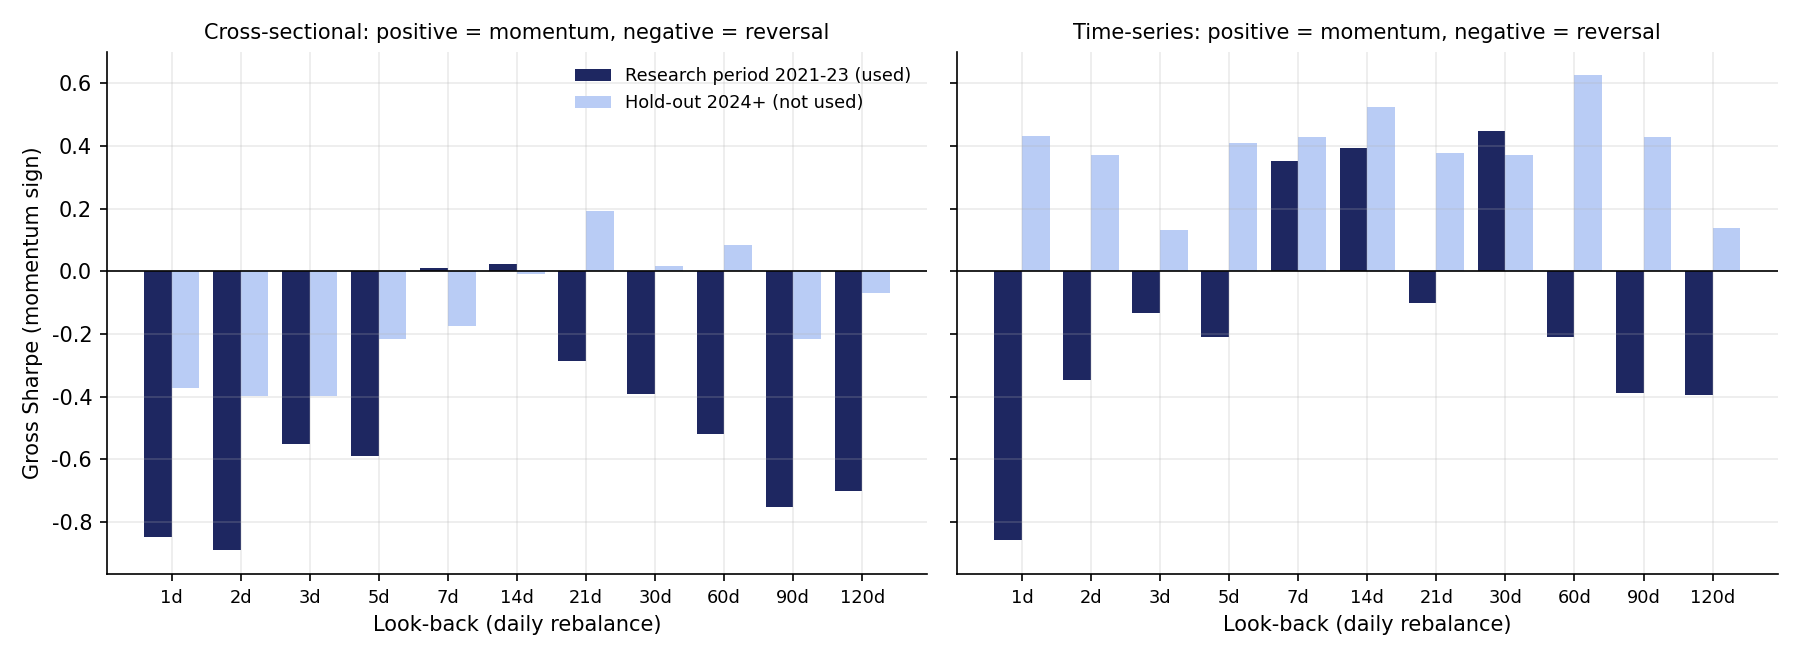

,Strategy,Gross IS,Gross OOS,Net20 IS,Net7 IS,Turnover
0,Cross-sectional L=1d,-0.846,-0.371,-5.078,-2.356,1.326
1,Time-series L=1d,-0.858,0.433,-2.120,-1.309,1.061
2,Cross-sectional L=2d,-0.890,-0.398,-3.830,-1.932,0.929
3,Time-series L=2d,-0.347,0.371,-1.199,-0.649,0.716
4,Cross-sectional L=3d,-0.549,-0.397,-3.014,-1.420,0.765
5,Time-series L=3d,-0.133,0.132,-0.839,-0.383,0.582
6,Cross-sectional L=5d,-0.590,-0.216,-2.519,-1.270,0.605
7,Time-series L=5d,-0.209,0.408,-0.770,-0.407,0.461
8,Cross-sectional L=7d,0.011,-0.175,-1.611,-0.559,0.512
9,Time-series L=7d,0.352,0.427,-0.115,0.187,0.384


In [9]:
display(Image("figures/A_horizon_scan.png"))
rd("A_horizon_scan")[["Strategy", "Gross IS", "Gross OOS", "Net20 IS", "Net7 IS", "Turnover"]]

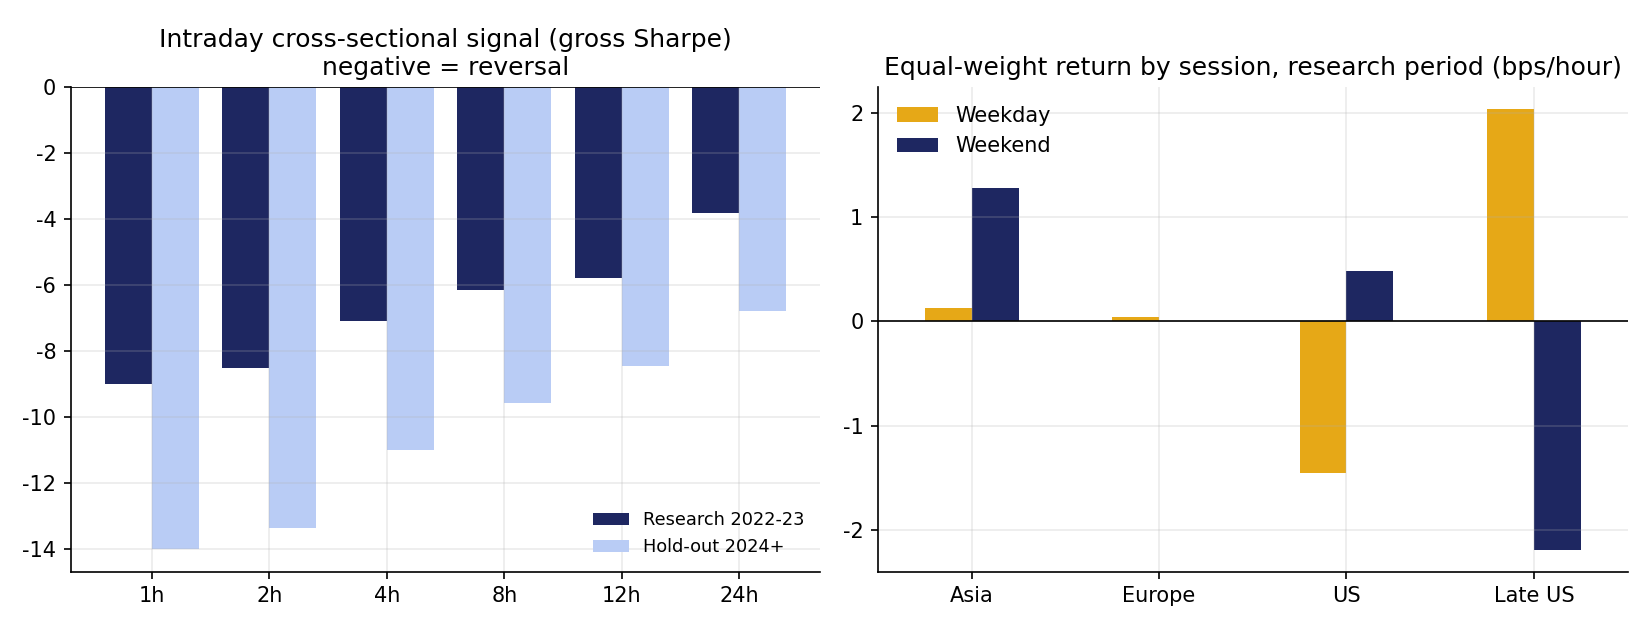

,lookback_hours,Gross Sharpe IS,Gross Sharpe OOS,Gross Sharpe,Gross bps/hour,Turnover/hour,Cost bps/hour @7,Net Sharpe @7,Net Sharpe @20
0,1,-8.992,-14.004,-12.059,-3.432,1.359,9.512,-43.630,-95.533
1,2,-8.522,-13.365,-11.492,-3.280,0.960,6.721,-34.067,-72.303
2,4,-7.090,-11.019,-9.503,-2.717,0.703,4.923,-26.245,-55.418
3,8,-6.152,-9.583,-8.261,-2.338,0.517,3.617,-20.798,-43.102
4,12,-5.797,-8.456,-7.429,-2.108,0.432,3.022,-17.926,-36.790
5,24,-3.809,-6.776,-5.640,-1.617,0.317,2.218,-13.305,-27.245


,Test,kind,Gross bps/day,Gross Sharpe IS,Gross Sharpe OOS,Net Sharpe @7,t-stat
0,Pre-US return -> US session,Time-series,-3.867,-0.959,0.075,-1.692,-0.926
1,Pre-US return -> US session,Cross-sectional,-2.982,-0.712,-0.669,-3.895,-1.735
2,Prior-day US session -> today's US session,Time-series,-5.699,-1.121,-0.090,-1.768,-1.385
3,Prior-day US session -> today's US session,Cross-sectional,0.137,0.094,-0.007,-3.166,0.086
4,US session -> late-US hours,Time-series,-1.115,0.357,-0.622,-2.464,-0.489
5,US session -> late-US hours,Cross-sectional,-4.959,-1.440,-2.348,-7.567,-5.103


In [10]:
display(Image("figures/C_intraday_sessions.png"))
display(rd("A2_intraday_horizon")); rd("E_frontrun_us_session")

### 5.2 Activity, seasonality, themes

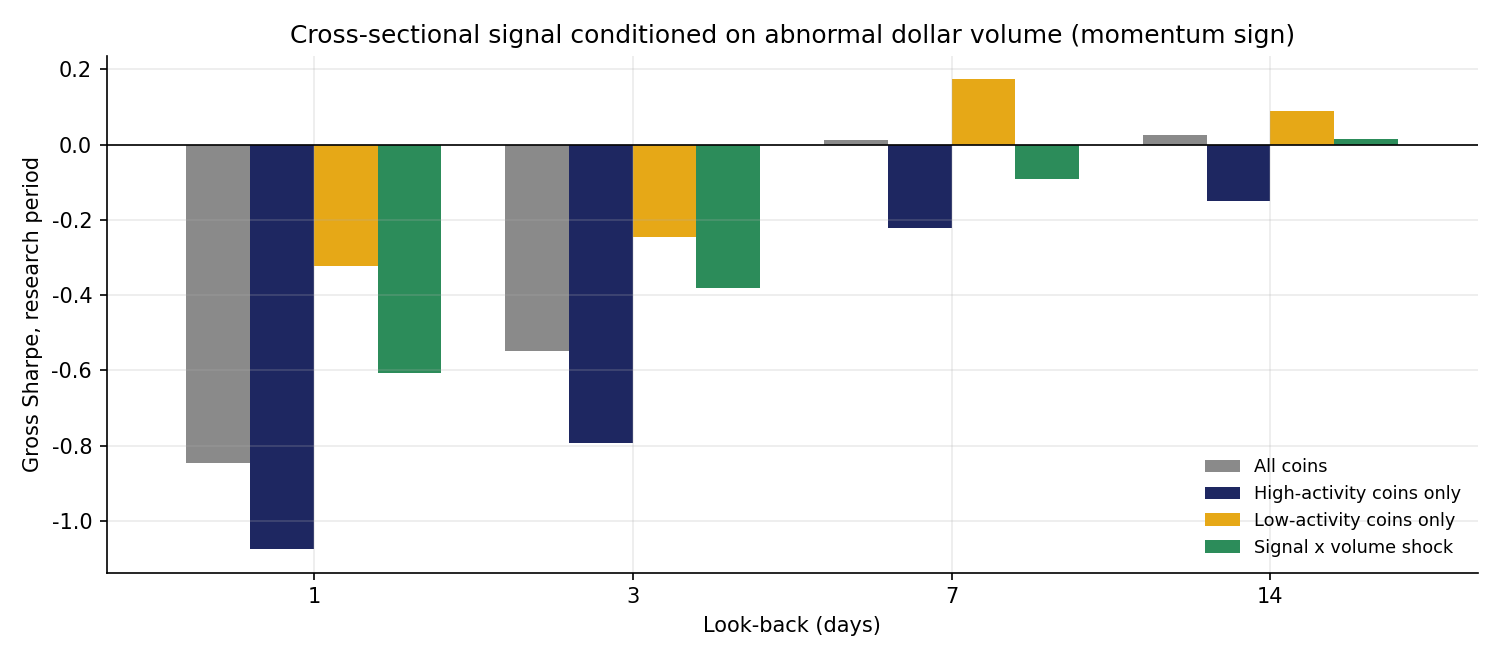

,Strategy,Gross IS,Gross OOS
0,CS L=1d | All coins,-0.846,-0.371
1,CS L=1d | High-activity coins only,-1.075,-0.215
2,CS L=1d | Low-activity coins only,-0.324,-0.362
3,CS L=1d | Signal x volume shock,-0.607,0.179
4,CS L=3d | All coins,-0.549,-0.397
5,CS L=3d | High-activity coins only,-0.793,-0.118
6,CS L=3d | Low-activity coins only,-0.245,-0.776
7,CS L=3d | Signal x volume shock,-0.381,0.256
8,CS L=7d | All coins,0.011,-0.175
9,CS L=7d | High-activity coins only,-0.221,-0.241


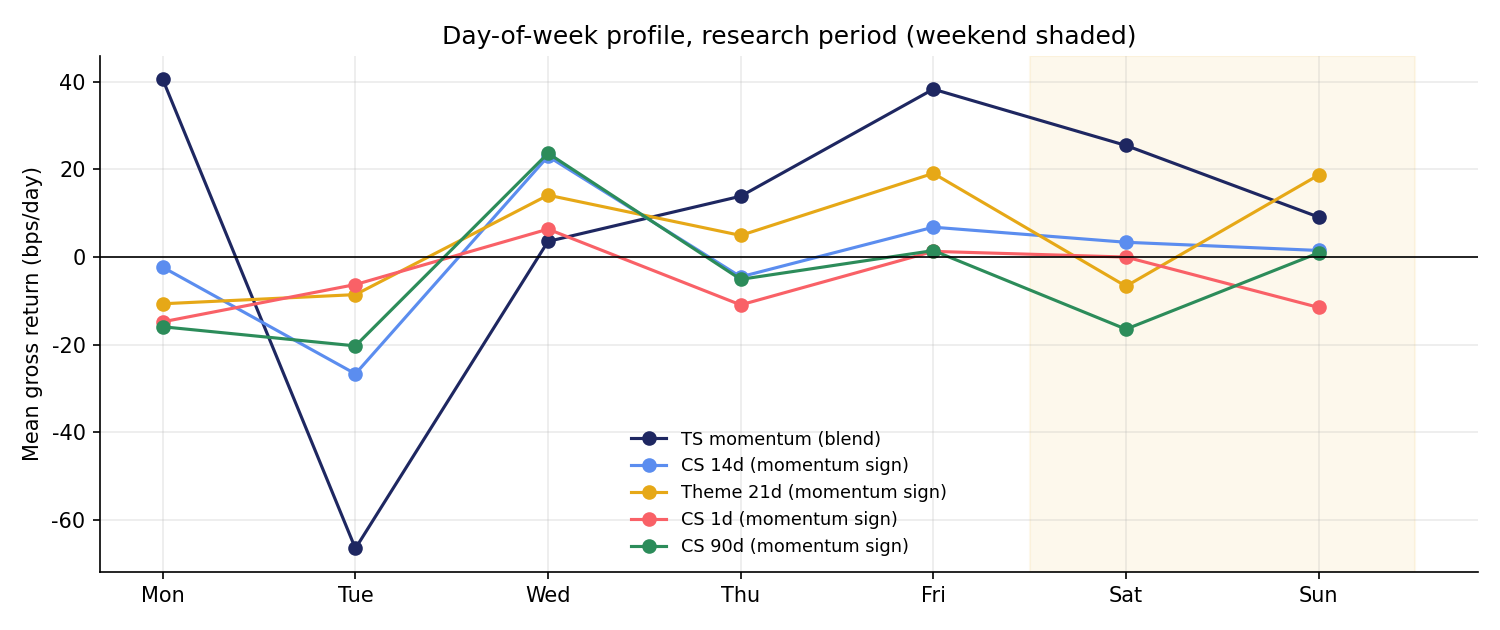

,Strategy,Weekday Sharpe,Weekend Sharpe,Weekday bps/day,Weekend bps/day,Mon bps,Tue bps,Wed bps,Thu bps,Fri bps,Sat bps,Sun bps
0,TS momentum (blend),0.323,1.367,5.994,17.264,40.484,-66.486,3.546,13.852,38.265,25.431,9.097
1,CS 14d (momentum sign),-0.114,0.464,-0.754,2.414,-2.342,-26.661,22.947,-4.533,6.790,3.350,1.478
2,Theme 21d (momentum sign),0.595,0.995,3.787,6.000,-10.679,-8.591,14.094,4.912,19.070,-6.676,18.675
3,CS 1d (momentum sign),-0.768,-1.088,-4.880,-5.768,-14.797,-6.292,6.348,-10.931,1.272,-0.024,-11.511
4,CS 90d (momentum sign),-0.526,-1.347,-3.237,-7.775,-15.922,-20.285,23.648,-5.106,1.457,-16.473,0.922


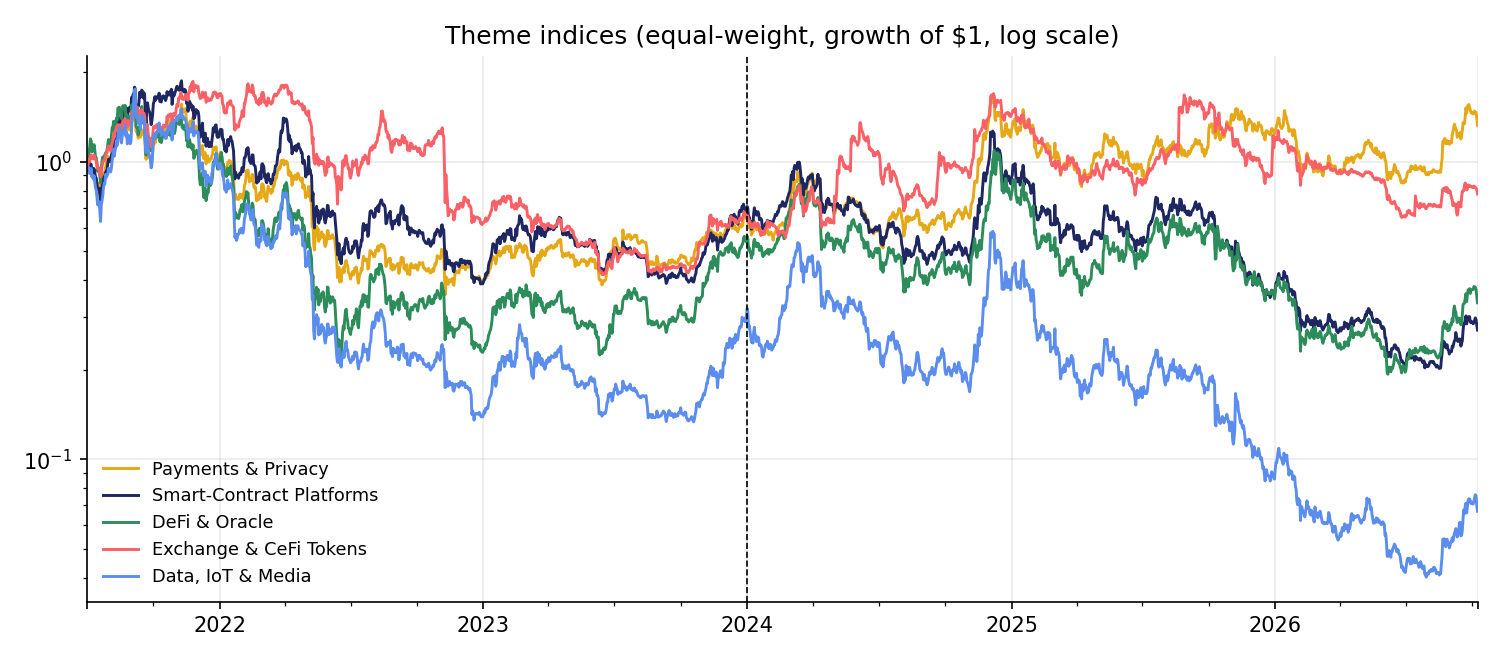

,Strategy,Gross IS,Gross OOS,Net20 IS,Turnover
0,Theme L=7d H=1d,0.481,0.175,-1.119,0.513
1,Theme L=7d H=7d,0.649,0.017,-0.235,0.269
2,Theme L=14d H=1d,0.995,-0.406,-0.127,0.377
3,Theme L=14d H=7d,1.096,0.100,0.570,0.169
4,Theme L=21d H=1d,0.706,0.433,-0.187,0.305
5,Theme L=21d H=7d,0.578,0.491,0.163,0.135
6,Theme L=30d H=1d,0.499,0.187,-0.219,0.246
7,Theme L=30d H=7d,0.224,0.191,-0.112,0.108
8,Theme L=60d H=1d,0.453,0.599,-0.136,0.164
9,Theme L=60d H=7d,0.301,0.534,0.048,0.070


In [11]:
display(Image("figures/B_activity_volume.png"))
display(rd("B_activity_volume")[["Strategy", "Gross IS", "Gross OOS"]])
display(Image("figures/C_day_of_week.png")); display(rd("C_weekday_weekend"))
display(Image("figures/D_theme_indices.png"))
rd("D_theme_momentum")[["Strategy", "Gross IS", "Gross OOS", "Net20 IS", "Turnover"]]

### 5.3 Correlation and macro

,Strategy,Gross IS,Gross OOS,Net7 IS,Turnover
0,Residual vs market L=1d,-0.826,-0.547,-2.482,1.327
1,Residual vs theme L=1d,-1.195,-0.522,-2.867,1.337
2,Residual vs market L=3d,-0.699,-0.031,-1.705,0.765
3,Residual vs theme L=3d,-1.006,-0.096,-1.968,0.767
4,Residual vs market L=7d,-0.358,0.093,-1.008,0.513
5,Residual vs theme L=7d,-0.401,-0.138,-1.045,0.510
6,Residual vs market L=14d,-0.344,0.217,-0.826,0.370
7,Residual vs theme L=14d,-0.540,-0.013,-1.006,0.368
8,Residual vs market L=30d,-0.671,0.055,-0.992,0.255
9,Residual vs theme L=30d,-0.776,0.041,-1.092,0.254


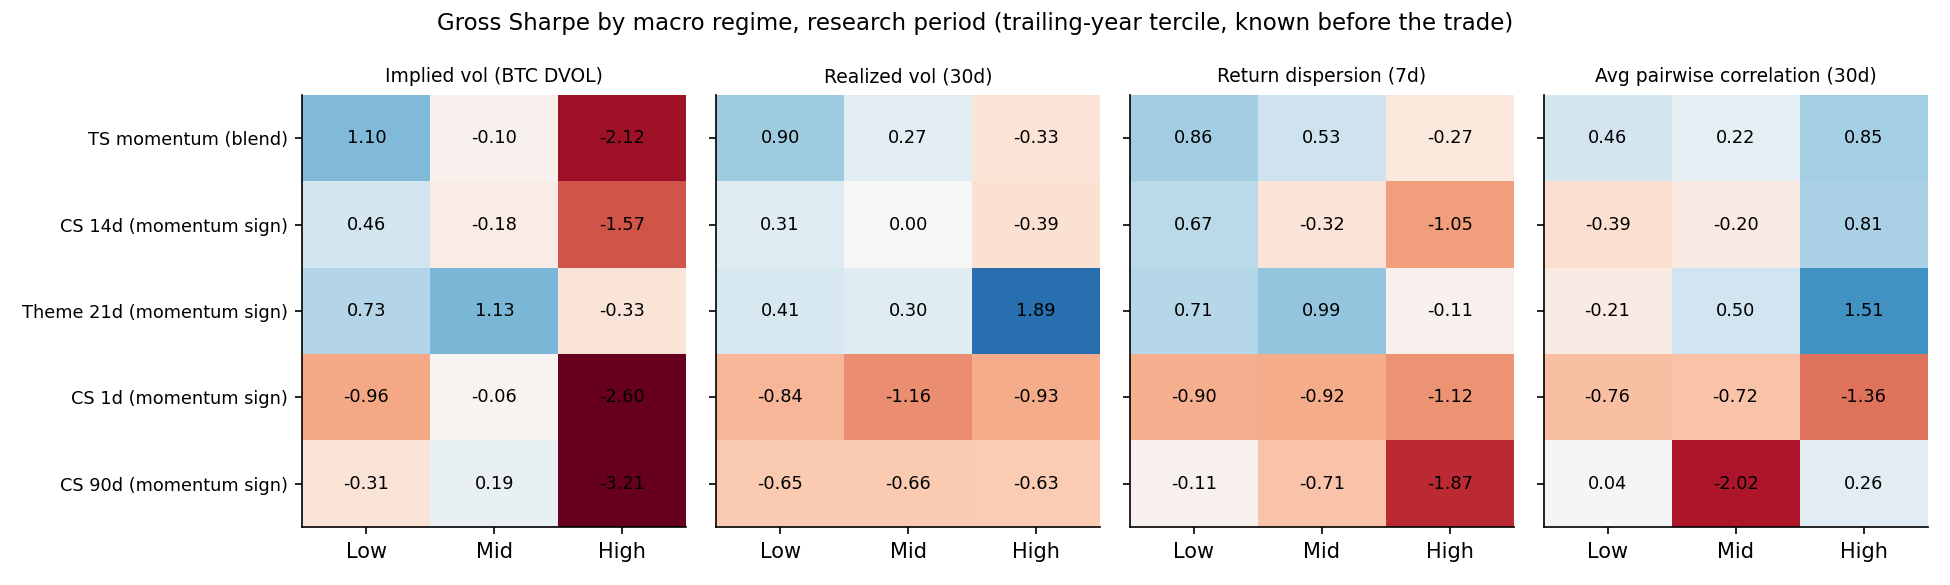

,Strategy,Indicator,Low Sharpe IS,Mid Sharpe IS,High Sharpe IS,Low Sharpe OOS,High Sharpe OOS
0,TS momentum (blend),Implied vol (BTC DVOL),1.101,-0.101,-2.122,0.960,-0.982
1,TS momentum (blend),Realized vol (30d),0.897,0.267,-0.334,1.045,0.226
2,TS momentum (blend),Return dispersion (7d),0.860,0.527,-0.272,0.309,1.510
3,TS momentum (blend),Avg pairwise correlation (30d),0.461,0.219,0.854,1.795,-0.031
4,CS 14d (momentum sign),Implied vol (BTC DVOL),0.462,-0.181,-1.568,0.506,-1.024
5,CS 14d (momentum sign),Realized vol (30d),0.305,0.001,-0.388,-0.368,0.440
6,CS 14d (momentum sign),Return dispersion (7d),0.665,-0.322,-1.050,-0.254,-0.469
7,CS 14d (momentum sign),Avg pairwise correlation (30d),-0.394,-0.199,0.806,-1.071,0.224
8,Theme 21d (momentum sign),Implied vol (BTC DVOL),0.731,1.133,-0.327,-0.311,0.563
9,Theme 21d (momentum sign),Realized vol (30d),0.410,0.296,1.894,0.478,1.064


In [12]:
display(rd("F_correlation")[["Strategy", "Gross IS", "Gross OOS", "Net7 IS", "Turnover"]])
display(Image("figures/G_macro_regimes.png"))
rd("G_macro_regimes")[["Strategy", "Indicator", "Low Sharpe IS", "Mid Sharpe IS", "High Sharpe IS", "Low Sharpe OOS", "High Sharpe OOS"]]

## 6. Mechanical selection

In [13]:
display(rd("H_signal_directions"))
sel = rd("H_candidate_selection")
display(sel.sort_values("Selection IS", ascending=False).groupby(["book", "family"]).head(1)
        [["Strategy", "book", "family", "Selection IS", "Net20 OOS", "Net7 OOS", "Turnover"]])
print(json.dumps({k: S[k] for k in ["momentum_members", "reversal_members", "execution_selected", "weighting_selected"]}, indent=2))

,family,signal,Gross IS (momentum sign),Direction (from IS),Gross OOS (momentum sign)
0,Cross-sectional,CS L=1,-0.846,reversal,-0.371
1,Cross-sectional,CS L=1 x volume,-0.607,reversal,0.179
2,Cross-sectional,CS L=2,-0.890,reversal,-0.398
3,Cross-sectional,CS L=2 x volume,-0.566,reversal,0.198
4,Cross-sectional,CS L=3,-0.549,reversal,-0.397
5,Cross-sectional,CS L=3 x volume,-0.381,reversal,0.256
6,Cross-sectional,CS L=5,-0.590,reversal,-0.216
7,Cross-sectional,CS L=5 x volume,-0.560,reversal,0.416
8,Cross-sectional,CS L=7,0.011,momentum,-0.175
9,Cross-sectional,CS L=7 x volume,-0.091,reversal,0.286


,Strategy,book,family,Selection IS,Net20 OOS,Net7 OOS,Turnover
60,Residual vs theme L=60 REV H=7,Reversal,Residual vs theme,0.814,-0.094,0.049,0.071
61,CS L=120 REV H=7,Reversal,Cross-sectional,0.668,-0.159,-0.073,0.049
62,Residual vs market L=60 REV H=7,Reversal,Residual vs market,0.647,-0.397,-0.259,0.069
0,Theme L=14 MOM H=7,Momentum,Theme,0.570,-0.454,-0.094,0.169
1,TS L=blend + DVOL filter MOM H=1,Momentum,Time-series,0.549,0.625,0.900,0.243
91,TS L=90 REV H=1,Reversal,Time-series,0.339,-0.579,-0.480,0.116
96,Short-term (1d) in high-vol regime REV H=2,Reversal,Short-term in high-vol regime,0.294,-1.759,-0.659,0.275
46,CS L=14 MOM H=3,Momentum,Cross-sectional,-0.557,-0.199,0.228,0.225
164,Cointegrated pairs REV,Reversal,Cointegrated pairs,-0.583,0.642,0.939,0.038


{
  "momentum_members": [
    "Theme L=14 MOM H=7",
    "TS L=blend + DVOL filter MOM H=1"
  ],
  "reversal_members": [
    "Residual vs theme L=60 REV H=7",
    "CS L=120 REV H=7",
    "Residual vs market L=60 REV H=7"
  ],
  "execution_selected": {
    "Momentum": "No-trade band 2%",
    "Reversal": "Hold 3d (overlapping)"
  },
  "weighting_selected": "Inverse volatility"
}


## 7. Execution and weighting

,Book,Execution,Turnover,Sharpe gross,Sharpe IS @book cost,Sharpe full @book cost,Sharpe full @other cost,Cost drag/yr @book cost
0,Momentum,Daily rebalance,0.206,0.984,0.652,0.481,0.807,0.104
1,Momentum,Hold 3d (overlapping),0.180,0.809,0.461,0.395,0.664,0.091
2,Momentum,Hold 7d (overlapping),0.146,0.638,0.249,0.319,0.526,0.074
3,Momentum,No-trade band 2%,0.163,0.954,0.750,0.539,0.808,0.082
4,Momentum,No-trade band 5%,0.043,-0.110,-0.403,-0.299,-0.176,0.022
5,Reversal,Daily rebalance,0.063,0.380,0.802,0.299,0.148,0.011
6,Reversal,Hold 3d (overlapping),0.057,0.409,0.841,0.335,0.196,0.010
7,Reversal,Hold 7d (overlapping),0.050,0.419,0.818,0.354,0.232,0.009
8,Reversal,No-trade band 2%,0.029,0.446,0.804,0.404,0.326,0.005
9,Reversal,No-trade band 5%,0.010,0.233,0.766,0.214,0.179,0.002


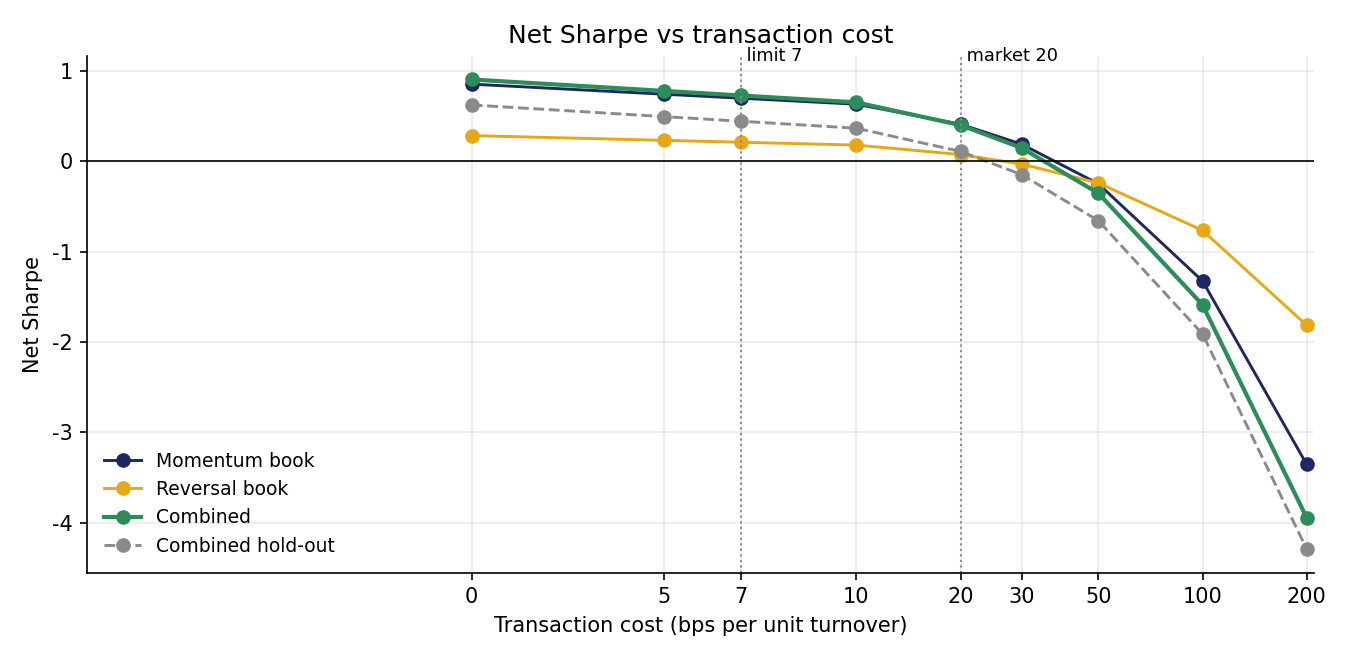

,cost_bps,Momentum book,Reversal book,Combined,Combined hold-out
0,0,0.855,0.285,0.907,0.624
1,5,0.744,0.233,0.780,0.496
2,7,0.699,0.212,0.729,0.444
3,10,0.633,0.180,0.653,0.367
4,20,0.411,0.075,0.401,0.110
5,30,0.191,-0.029,0.149,-0.146
6,50,-0.248,-0.239,-0.353,-0.656
7,100,-1.324,-0.764,-1.588,-1.911
8,200,-3.355,-1.815,-3.946,-4.293


,Method,Avg weight Momentum,Avg weight Reversal,Sharpe IS,Sharpe OOS,Sharpe
0,Equal weight,0.500,0.500,0.860,0.201,0.488
1,Inverse volatility,0.426,0.574,0.933,0.201,0.505
2,Risk parity (ERC),0.426,0.574,0.933,0.201,0.505
3,Mean-variance (shrunk),0.469,0.531,0.603,-0.009,0.215


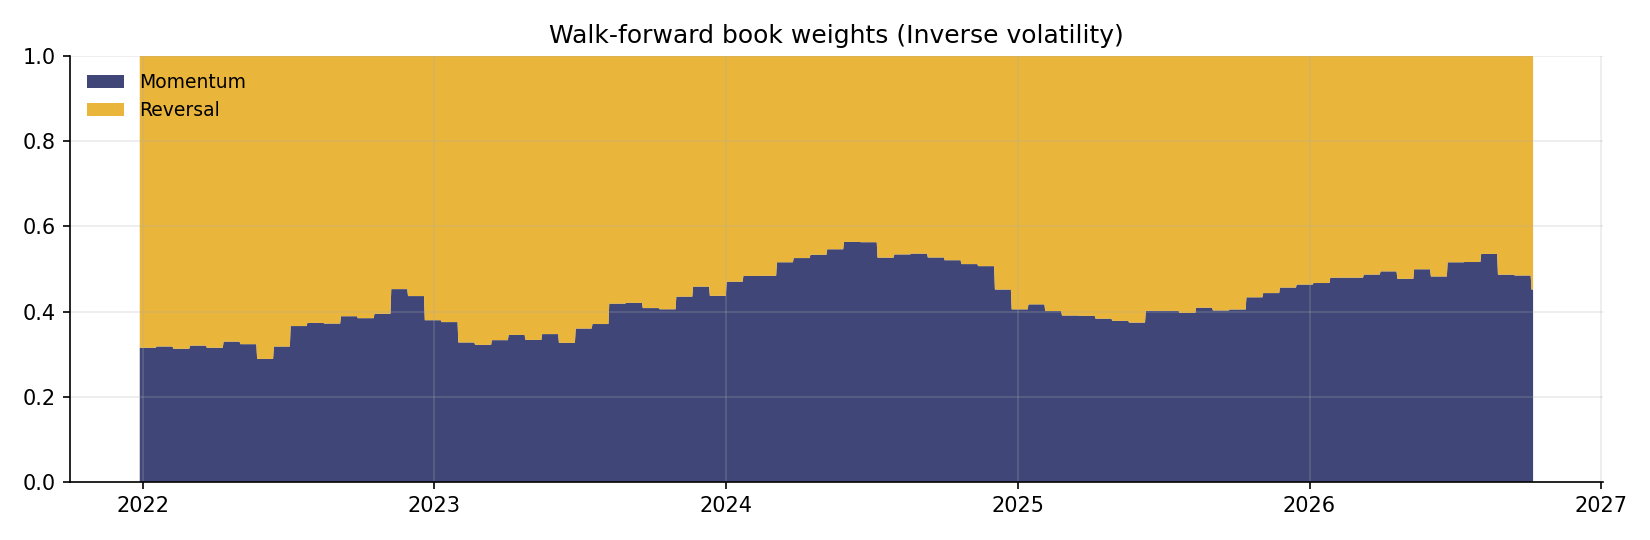

,Momentum book,Reversal book,Cointegrated pairs,BTC
Unnamed: 0,,,,
Momentum book,1.000,-0.106,-0.148,-0.206
Reversal book,-0.106,1.000,-0.004,0.026
Cointegrated pairs,-0.148,-0.004,1.000,0.070
BTC,-0.206,0.026,0.070,1.000


,Construction,Momentum Sharpe IS,Momentum Sharpe OOS,Reversal Sharpe IS,Reversal Sharpe OOS,Combined Sharpe IS,Combined Sharpe OOS
0,Final: top-3 family ensembles,0.543,0.301,0.658,-0.068,0.933,0.201
1,Single IS-best strategy per book,0.542,-0.300,0.696,0.078,0.984,-0.235


In [14]:
display(rd("H_execution_variants")); display(Image("figures/H_cost_sweep.png")); display(rd("H_cost_sweep"))
display(rd("I_weighting_methods")); display(Image("figures/I_sleeve_weights.png"))
display(rd("I_sleeve_correlation").set_index("Unnamed: 0")); rd("I_selection_robustness")

## 8. Conclusion
* With a survivorship-free universe and an honest protocol, the combined portfolio's hold-out Sharpe is
  0.20 with an alpha t-statistic of 0.52: market-neutral (correlation to BTC -0.12)
  but not statistically significant.
* Time-series momentum with a DVOL filter, selected on 2021-2023 alone, is the component that held up out of sample.
* The cross-section shows reversal at short and long horizons, but turnover and instability erase most of it after costs.
